# Econ 521 — Lab: Regression Discontinuity, Part 2 — SOLUTIONS
### Making an RD credible: bandwidths, falsification, fuzzy designs, and time as the running variable

**Friday, 9 October 2026 — 50 minutes**

Last week we built a sharp RD by hand and estimated the effect of DUI punishment on recidivism.
We left four questions open, and they are the four a referee will ask:

1. You picked the bandwidth and the polynomial order. Why those?
2. How do I know drivers aren't sorting across 0.08?
3. What if crossing the cutoff only changes the *probability* of treatment?
4. What if the running variable is time?

**Plan**

| Minutes | Section |
|---|---|
| 0–3 | 0. Setup and recap |
| 3–15 | 1. Modern estimation: `rdrobust` |
| 15–31 | 2. The falsification toolkit |
| 31–41 | 3. Fuzzy RD is IV at the cutoff |
| 41–48 | 4. RD in time, and why it's different |
| 48–50 | 5. Writing up an RD in your final project |

References for today: Cattaneo & Titiunik (2022, *Annual Review of Economics*) for sections 1–3,
Hausman & Rapson (2018, *Annual Review of Resource Economics*) for section 4. Both are posted.

> ### SOLUTION KEY
> This is the worked version of **RD Lab 2**. Every `# TODO` is filled in and the
> discussion after each exercise gives the answer you were meant to arrive at.
> Try the blank version first — reading a solved RD and writing one are different skills.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# If these are missing: pip install rdrobust rddensity
from rdrobust import rdrobust, rdplot
from rddensity import rddensity

plt.rcParams.update({"figure.figsize": (7.5, 4.5), "figure.dpi": 110,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
rng = np.random.default_rng(521)

URL = "https://raw.githubusercontent.com/scunning1975/mixtape/master/hansen_dwi.dta"
try:
    dwi = pd.read_stata("data/hansen_dwi.dta")
except Exception:
    dwi = pd.read_stata(URL)
dwi = dwi[["bac1", "recidivism", "male", "white", "aged", "acc", "year"]].copy()
dwi["x"] = dwi.bac1 - 0.08
dwi["D"] = (dwi.bac1 >= 0.08).astype(int)
print(f"{len(dwi):,} stops;  base recidivism rate = {dwi.recidivism.mean():.3f}")

214,558 stops;  base recidivism rate = 0.118


## 1. Modern estimation: `rdrobust`

Last week we ran

```python
smf.ols("recidivism ~ D + x + D:x", data=dwi[dwi.x.abs() <= 0.05])
```

and got −0.023. With `h = 0.02` we got −0.015. Both are defensible. That discretion is exactly
what `rdrobust` is designed to remove. Three ingredients:

**(a) A data-driven bandwidth.** Choose $h$ to minimize the asymptotic MSE of the point
estimator — the formal version of the bias–variance trade-off you watched last week.

**(b) A kernel.** The triangular kernel weights observations by closeness to the cutoff instead
of treating a point at $h$ the same as a point at the cutoff.

**(c) Robust bias-corrected inference.** This is the subtle one. If $h$ is MSE-optimal, the
local linear fit carries a *non-negligible* approximation bias by construction. The usual
t-statistic ignores it, so a nominal 95% confidence interval covers roughly 80% of the time
(Calonico, Cattaneo & Titiunik 2014). `rdrobust` estimates the bias, subtracts it, and inflates
the standard error to account for having estimated it. Report the **robust** interval.

In [3]:
def rd_table(results):
    rows = []
    for label, o in results.items():
        rows.append({"spec": label,
                     "tau": o.coef.iloc[0, 0],
                     "se (conv)": o.se.iloc[0, 0],
                     "p (conv)": o.pv.iloc[0, 0],
                     "p (robust)": o.pv.iloc[2, 0],
                     "robust 95% CI": f"[{o.ci.iloc[2,0]:+.4f}, {o.ci.iloc[2,1]:+.4f}]",
                     "h": o.bws.loc["h", "left"],
                     "N eff": int(sum(o.N_h))})
    return pd.DataFrame(rows).set_index("spec").round(4)

# vce="hc1": the default nearest-neighbour variance estimator is very slow at n = 200k.
main = rdrobust(y=dwi.recidivism, x=dwi.bac1, c=0.08, vce="hc1")
print(main)

Mass points detected in the running variable.
Call: rdrobust

Sharp RD estimates using local polynomial regression.

Number of Observations:                214558
Polynomial Order Est. (p):                  1
Polynomial Order Bias (q):                  2
Kernel:                            Triangular
Bandwidth Selection:                    mserd
Var-Cov Estimator:                        HC1

                                Left      Right
------------------------------------------------
Number of Observations         22101     192457
Number of Unique Obs.             80        319
Number of Effective Obs.       15286      38848
Bandwidth Estimation           0.029      0.029
Bandwidth Bias                 0.046      0.046
rho (h/b)                      0.627      0.627

Method             Coef.     S.E.   z-stat    P>|z|       95% CI      
-------------------------------------------------------------------------
Conventional      -0.016    0.006   -2.641   8.260e-03   [-0.028, -0.004]
R

In [4]:
res = {
    "p=1 (default)"      : main,
    "p=2 (local quad)"   : rdrobust(y=dwi.recidivism, x=dwi.bac1, c=0.08, p=2, vce="hc1"),
    "uniform kernel"     : rdrobust(y=dwi.recidivism, x=dwi.bac1, c=0.08, kernel="uniform", vce="hc1"),
    "CER-optimal bw"     : rdrobust(y=dwi.recidivism, x=dwi.bac1, c=0.08, bwselect="cerrd", vce="hc1"),
    "+ covariates"       : rdrobust(y=dwi.recidivism, x=dwi.bac1, c=0.08, vce="hc1",
                                    covs=dwi[["male", "white", "aged", "acc"]]),
}
rd_table(res)

Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.


,tau,se (conv),p (conv),p (robust),robust 95% CI,h,N eff
spec,,,,,,,
p=1 (default),-0.0162,0.0061,0.0083,0.0443,"[-0.0293, -0.0004]",0.0290,54134
p=2 (local quad),-0.0140,0.0085,0.0994,0.1653,"[-0.0329, +0.0056]",0.0332,61091
uniform kernel,-0.0150,0.0066,0.0226,0.0663,"[-0.0299, +0.0010]",0.0203,38349
CER-optimal bw,-0.0135,0.0082,0.0989,0.1286,"[-0.0301, +0.0038]",0.0157,29304
+ covariates,-0.0159,0.0061,0.0095,0.0522,"[-0.0284, +0.0001]",0.0290,54134


### Read this table carefully — it is the honest version of last week's result

The MSE-optimal bandwidth is about **0.029**, considerably narrower than the 0.05 window we
used by hand, and the point estimate is correspondingly smaller: about **−0.016** rather than
−0.023. The robust p-value sits just under 0.05.

So: the deterrent effect is there, the sign is stable across every specification, the magnitude
is around 1.5–2 percentage points on a base of 11 — but it is **not** as sharply estimated as a
single hand-picked bandwidth made it look. That sentence belongs in the paper. Papers that only
ever report the specification with the smallest p-value are the reason `rdrobust` exists.

Two other things to notice:

* **Covariates barely move the estimate.** They should not. In an RD, covariates buy precision,
  not identification (Calonico et al. 2019). If adding controls *does* move your RD estimate a
  lot, that is a symptom, not a fix.
* **`rdrobust` warns about mass points.** BAC is recorded to three decimals, so the running
  variable is discrete: 399 distinct values, not 214,558. With many mass points, continuity
  methods are still fine, but the effective sample size for the asymptotics is the number of
  mass points near the cutoff, not the number of drivers (Cattaneo & Titiunik §3.5).

Mass points detected in the running variable.


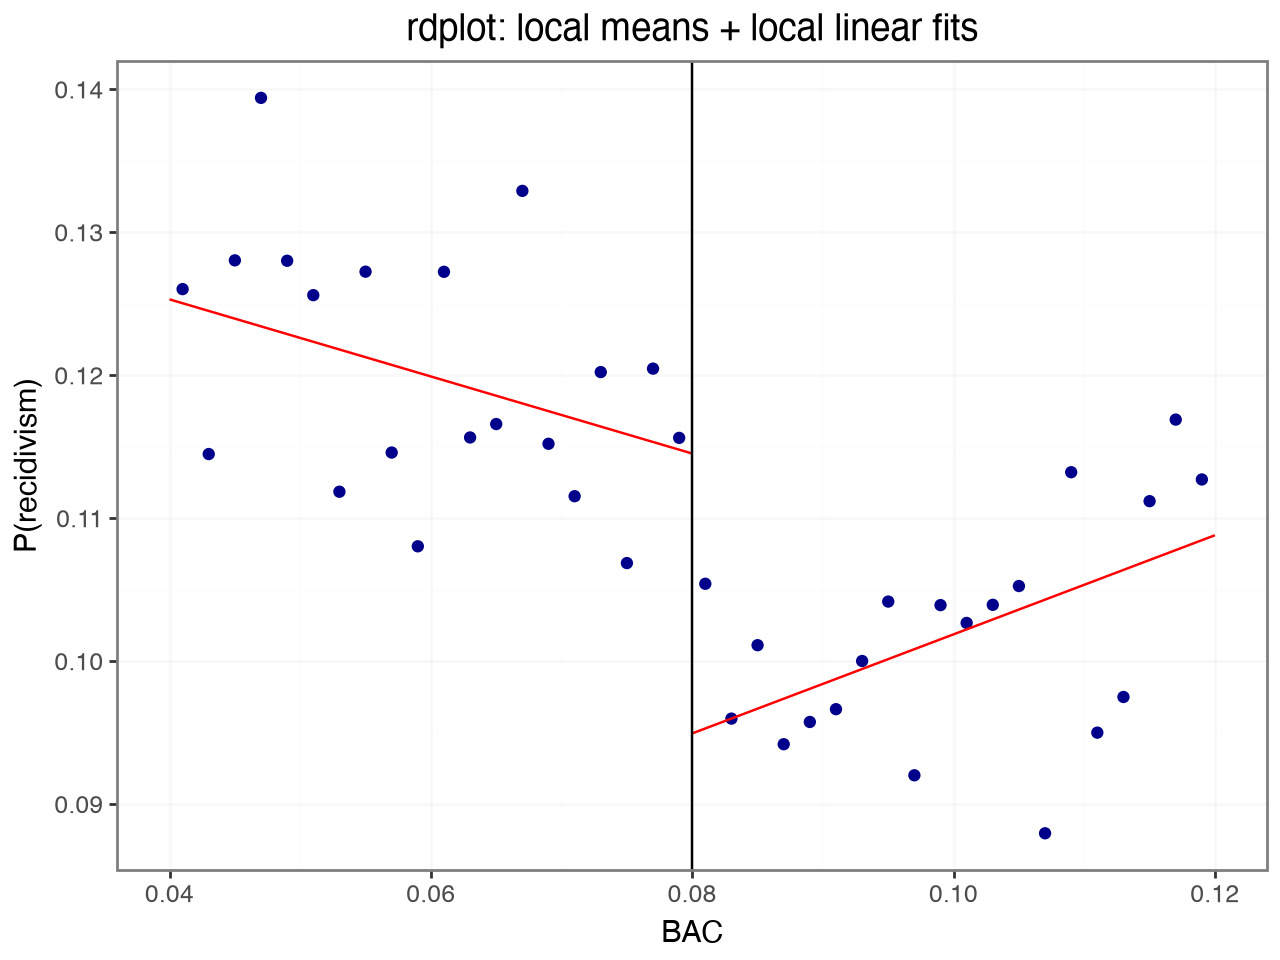

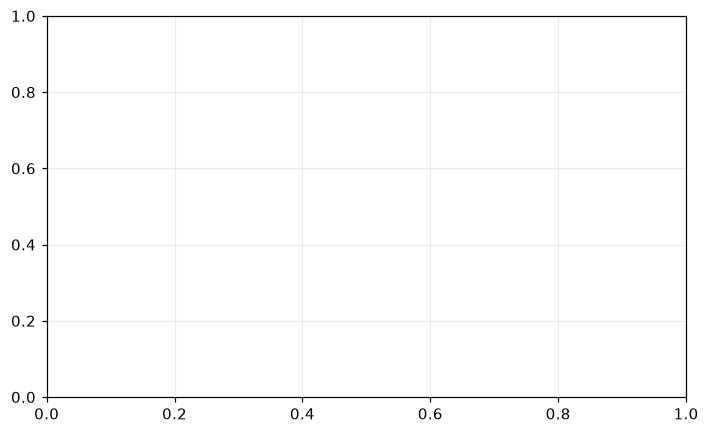

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
w = dwi[(dwi.bac1 >= 0.04) & (dwi.bac1 <= 0.12)]
rdplot(y=w.recidivism, x=w.bac1, c=0.08, p=1, nbins=[20, 20],
       x_label="BAC", y_label="P(recidivism)",
       title="rdplot: local means + local linear fits")
plt.show()

### Your turn (Exercise 1)

Trace sensitivity to the bandwidth explicitly. This plot appears in most good RD papers.

Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.


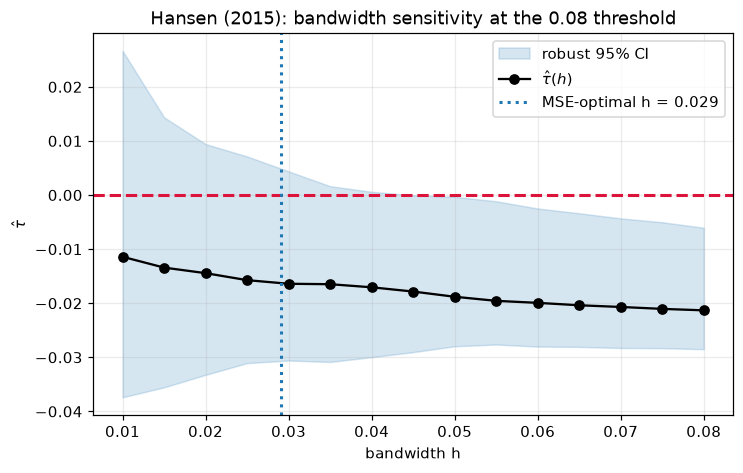

    h     tau      lo      hi  N eff
0.010 -0.0114 -0.0374  0.0267  18897
0.015 -0.0134 -0.0355  0.0144  27517
0.020 -0.0144 -0.0332  0.0094  36575
0.025 -0.0157 -0.0311  0.0071  47205
0.030 -0.0164 -0.0306  0.0044  54338
0.035 -0.0165 -0.0309  0.0016  62901
0.040 -0.0171 -0.0300  0.0006  71316
0.045 -0.0178 -0.0290 -0.0000  80022
0.050 -0.0188 -0.0280 -0.0003  90074
0.055 -0.0196 -0.0276 -0.0012  96892
0.060 -0.0199 -0.0280 -0.0025 105339
0.065 -0.0204 -0.0281 -0.0034 113735
0.070 -0.0207 -0.0283 -0.0043 121966
0.075 -0.0210 -0.0283 -0.0050 129843
0.080 -0.0213 -0.0285 -0.0060 138249


In [6]:
grid = np.arange(0.01, 0.081, 0.005)
rows = []
for h in grid:
    o = rdrobust(y=dwi.recidivism, x=dwi.bac1, c=0.08, h=h, vce="hc1")
    rows.append({"h": h, "tau": o.coef.iloc[0, 0],
                 "lo": o.ci.iloc[2, 0], "hi": o.ci.iloc[2, 1],
                 "N eff": int(sum(o.N_h))})
path = pd.DataFrame(rows)
h_opt = main.bws.loc["h", "left"]

fig, ax = plt.subplots()
ax.fill_between(path.h, path.lo, path.hi, alpha=0.18, color="tab:blue",
                label="robust 95% CI")
ax.plot(path.h, path.tau, "o-", color="black", lw=1.5, label=r"$\hat\tau(h)$")
ax.axhline(0, color="crimson", ls="--", lw=2)
ax.axvline(h_opt, color="tab:blue", ls=":", lw=2, label=f"MSE-optimal h = {h_opt:.3f}")
ax.set_xlabel("bandwidth h"); ax.set_ylabel(r"$\hat\tau$")
ax.set_title("Hansen (2015): bandwidth sensitivity at the 0.08 threshold")
ax.legend(); plt.show()

print(path.round(4).to_string(index=False))

**Answer.** The estimate drifts monotonically away from zero as the window widens: about
$-0.011$ at $h = 0.01$, $-0.016$ at the MSE-optimal $0.029$, $-0.021$ at $h = 0.08$. The
interval tightens at the same time, so the widest window gives the most "significant" result.

**That drift is bias, not effect.** Two reasons to say so:

1. **The shape.** A real treatment effect that varied with BAC would have no reason to be a
   smooth monotone function of *the researcher's bandwidth choice*. A functional-form
   approximation error does exactly this: the wider the window, the more the straight line has
   to compromise between the curvature far from the cutoff and the fit at the cutoff.
2. **The economics of the alternative.** To read the drift as signal you would have to claim
   the deterrent effect is systematically larger for drivers at 0.03 and 0.13 than for drivers
   at 0.079 and 0.081. Nobody would defend that, and in any case an RD cannot identify it —
   those units are far from the cutoff and have no comparison group.

Recall the picture from last week: the BAC–recidivism relationship slopes *down*. Widening the
window pulls in low-BAC drivers on the left with mechanically higher recidivism, which inflates
the measured gap at the cutoff. The direction of the drift is exactly what that slope predicts.

The honest summary for a paper: *"the point estimate ranges from $-0.011$ to $-0.021$ across
bandwidths from 0.01 to 0.08, with the MSE-optimal bandwidth giving $-0.016$; the robust
confidence interval excludes zero at the optimal bandwidth and at wider ones, but not at
bandwidths below roughly 0.025."* That sentence costs you nothing and buys you a referee's
trust.

## 2. The falsification toolkit

RD assumptions are untestable. What you *can* do is expose them to many chances to fail. Four
standard tests, all of which Hansen runs.

### 2.1 Manipulation: is the density of the running variable smooth at the cutoff?

If people could choose their side of the cutoff, you would expect to find too few just below
and too many just above (or vice versa). You cannot test sorting directly, but you can test
this implication of it: McCrary (2008), modernized by Cattaneo, Jansson & Ma (2020).

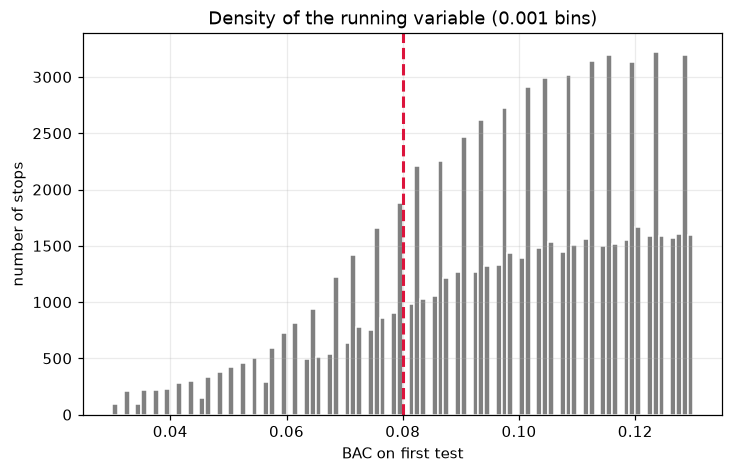

density test  t = -0.139   p = 0.890
estimated density just below / just above : 4.557 / 4.533


In [7]:
fig, ax = plt.subplots()
bins = np.arange(0.03, 0.1301, 0.001)
ax.hist(dwi.bac1[(dwi.bac1 >= 0.03) & (dwi.bac1 <= 0.13)], bins=bins, color="grey", edgecolor="white")
ax.axvline(0.08, color="crimson", ls="--", lw=2)
ax.set_xlabel("BAC on first test"); ax.set_ylabel("number of stops")
ax.set_title("Density of the running variable (0.001 bins)")
plt.show()

dens = rddensity(dwi.bac1.values, c=0.08)
print(f"density test  t = {dens.test['t_jk']:+.3f}   p = {dens.test['p_jk']:.3f}")
print(f"estimated density just below / just above : {dens.hat['left']:.3f} / {dens.hat['right']:.3f}")

No jump: $p \approx 0.89$. This is what the institution predicts. A driver cannot blow a
precise 0.079, and the officer administering the test does not know the exact reading until
it appears.

Hansen makes the stronger version of this argument: an officer *could* in principle nudge
borderline cases, and that is worth checking. The flat density is the evidence that they don't.

**Where this test is useless:** when the running variable has a mechanically uniform density.
That is the time case, and we come back to it in section 4.

### 2.2 Balance: do predetermined characteristics jump?

The RD logic says units just above and just below should look the same in everything determined
*before* treatment. So run the identical RD with a covariate as the outcome and hope for zeros.

In [8]:
bal = {cv: rdrobust(y=dwi[cv], x=dwi.bac1, c=0.08, vce="hc1")
       for cv in ["male", "white", "aged", "acc"]}
print(rd_table(bal).to_string())

Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
          tau  se (conv)  p (conv)  p (robust)       robust 95% CI       h  N eff
spec                                                                             
male  -0.0182     0.0097    0.0602      0.0374  [-0.0455, -0.0014]  0.0191  36575
white -0.0003     0.0084    0.9746      0.7099  [-0.0238, +0.0162]  0.0190  36575
aged  -0.1076     0.2442    0.6594      0.7320  [-0.6917, +0.4859]  0.0253  47205
acc   -0.0074     0.0073    0.3111      0.2247  [-0.0280, +0.0066]  0.0168  31103


Three of four are flat. `male` shows a jump of about −1.8 percentage points with a robust
p-value near 0.04.

How worried should you be? Some discipline here:

* With four independent tests at the 5% level, the chance of at least one rejection under the
  null is about 19%. One marginal rejection out of four is unremarkable.
* The magnitude is small relative to the mean (0.79) and does not line up with a story in which
  the outcome gap is driven by composition.
* The decisive check is whether the main estimate moves when you adjust for it. From the table
  in section 1: −0.0162 unadjusted, −0.0159 adjusted. It doesn't.

You still **report it**. Hiding a failed balance test and getting caught is a career problem;
reporting it with the three lines above is a paragraph.

### 2.3 Placebo cutoffs

If the jump at 0.08 is caused by the law, there should be no jump anywhere else. Run the same
RD at fake cutoffs — and run them **one side at a time**, so the real treatment never
contaminates the placebo window.

In [9]:
below = dwi[dwi.bac1 <  0.08]      # never treated
above = dwi[dwi.bac1 >= 0.08]      # always treated

plac = {}
for cc in [0.05, 0.06, 0.07]:
    plac[f"placebo c={cc:.2f} (below only)"] = rdrobust(y=below.recidivism, x=below.bac1, c=cc, vce="hc1")
for cc in [0.10, 0.12, 0.14]:
    plac[f"placebo c={cc:.2f} (above only)"] = rdrobust(y=above.recidivism, x=above.bac1, c=cc, vce="hc1")
print(rd_table(plac).to_string())

Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
                                tau  se (conv)  p (conv)  p (robust)       robust 95% CI       h  N eff
spec                                                                                                   
placebo c=0.05 (below only) -0.0125     0.0221    0.5705      0.7588  [-0.0606, +0.0442]  0.0118   5044
placebo c=0.06 (below only)  0.0138     0.0185    0.4560      0.5298  [-0.0314, +0.0610]  0.0088   6444
placebo c=0.07 (below only) -0.0103     0.0127    0.4175      0.5087  [-0.0448, +0.0222]  0.0106  12885
placebo c=0.10 (above only)  0.0019     0.0065    0.7704      0.6458  [-0.0125, +0.0202]  0.0149  40388
placebo c=0.12 (above only) -0.0054     0.0059    0.3577      0.3081  [-0.0209, +0.0066]  0.0176  54

All six are indistinguishable from zero. Nothing special happens at an arbitrary BAC — only at
the one the legislature wrote down.

### 2.4 Donut hole

Sometimes the observations *closest* to the cutoff are the suspicious ones: rounding, heaping,
last-second behavior, administrative discretion. Drop them and see whether the result survives.

In [10]:
donut = {}
for g in [0.0, 0.001, 0.002, 0.005]:
    s = dwi if g == 0 else dwi[(dwi.bac1 - 0.08).abs() >= g]
    donut[f"donut +/- {g}"] = rdrobust(y=s.recidivism, x=s.bac1, c=0.08, vce="hc1")
print(rd_table(donut).to_string())

Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
                    tau  se (conv)  p (conv)  p (robust)       robust 95% CI       h  N eff
spec                                                                                       
donut +/- 0.0   -0.0162     0.0061    0.0083      0.0443  [-0.0293, -0.0004]  0.0290  54134
donut +/- 0.001 -0.0199     0.0072    0.0058      0.0279  [-0.0380, -0.0022]  0.0254  45323
donut +/- 0.002 -0.0193     0.0077    0.0120      0.0629  [-0.0370, +0.0010]  0.0272  46896
donut +/- 0.005 -0.0182     0.0119    0.1276      0.3127  [-0.0459, +0.0147]  0.0239  34159


The point estimate is stable — it actually grows slightly — while the interval widens, because
a donut throws away the most informative observations. A donut that *kills* a result is a red
flag; a donut that widens the interval is just arithmetic.

### Your turn (Exercise 2)

Take the full falsification kit to the **0.15** aggravated-DUI threshold, which you estimated
last week.

density test at 0.15 :  t = -1.172   p = 0.241


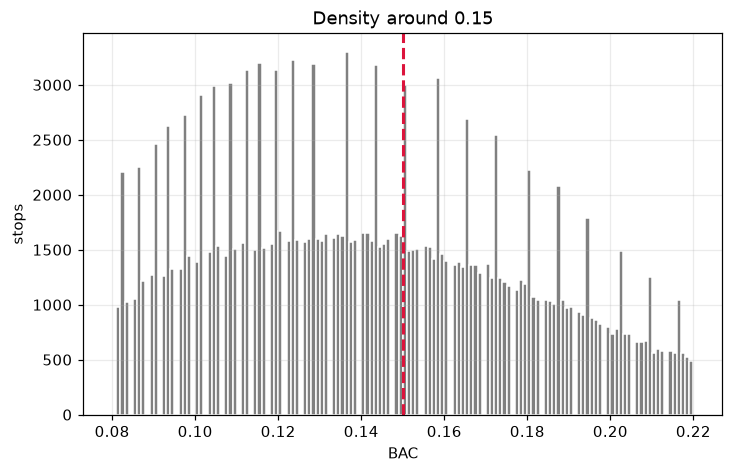

Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.
Mass points detected in the running variable.

=== effect at 0.15 ===
                        tau  se (conv)  p (conv)  p (robust)       robust 95% CI       h  N eff
spec                                                                                           
recidivism at c=0.15 -0.003     0.0054    0.5824      0.7439  [-0.0148, +0.0106]  0.0228  67924

=== balance at 0.15 ===
          tau  se (conv)  p (conv)  p (robust)       robust 95% CI       h  N eff
spec                                                                             
male   0.0085     0.0071    0.2267      0.2219  [-0.0062, +0.0267]  0.0208  62196
whi

In [11]:
# Keep the 0.08 cutoff out of every window: work only with drivers at or above 0.08.
hi = dwi[dwi.bac1 >= 0.08]

# 1. Manipulation test at 0.15
dens15 = rddensity(hi.bac1.values, c=0.15)
print(f"density test at 0.15 :  t = {dens15.test['t_jk']:+.3f}   p = {dens15.test['p_jk']:.3f}")

fig, ax = plt.subplots()
ax.hist(hi.bac1[hi.bac1 <= 0.22], bins=np.arange(0.08, 0.2201, 0.001),
        color="grey", edgecolor="white")
ax.axvline(0.15, color="crimson", ls="--", lw=2)
ax.set_xlabel("BAC"); ax.set_ylabel("stops"); ax.set_title("Density around 0.15")
plt.show()

# 2. The effect itself, with a data-driven bandwidth
main15 = rdrobust(y=hi.recidivism, x=hi.bac1, c=0.15, vce="hc1")

# 3. Covariate balance
bal15 = {cv: rdrobust(y=hi[cv], x=hi.bac1, c=0.15, vce="hc1")
         for cv in ["male", "white", "aged", "acc"]}

# 4. Placebo cutoffs, one side at a time
below15 = dwi[(dwi.bac1 >= 0.08) & (dwi.bac1 < 0.15)]
above15 = dwi[dwi.bac1 >= 0.15]
plac15 = {}
for cc in [0.12, 0.13]:
    plac15[f"placebo c={cc} (below)"] = rdrobust(y=below15.recidivism, x=below15.bac1, c=cc, vce="hc1")
for cc in [0.17, 0.19]:
    plac15[f"placebo c={cc} (above)"] = rdrobust(y=above15.recidivism, x=above15.bac1, c=cc, vce="hc1")

print("\n=== effect at 0.15 ===")
print(rd_table({"recidivism at c=0.15": main15}).to_string())
print("\n=== balance at 0.15 ===")
print(rd_table(bal15).to_string())
print("\n=== placebo cutoffs ===")
print(rd_table(plac15).to_string())

**Answer.** Every falsification test passes, and the result disappears.

| Check | Result |
|---|---|
| Density at 0.15 | $p \approx 0.24$ — no sorting |
| Balance on `male`, `white`, `aged`, `acc` | all $p > 0.19$ — clean |
| Four placebo cutoffs (0.12, 0.13, 0.17, 0.19) | all $p > 0.27$ — nothing fires |
| **Effect on recidivism** | $\hat\tau \approx -0.003$, MSE-optimal $h \approx 0.023$, **robust $p \approx 0.74$** |

Compare that with last week's hand-picked window, which gave $-0.0067$ with $t \approx 2$. The
window was doing the work.

**The three sentences asked for.** The 0.15 design is internally about as credible as the 0.08
design: nothing sorts across the threshold, no covariate jumps, and no placebo cutoff produces
a spurious discontinuity. It is weaker in *power relative to the size of the effect*, because
the treatment at 0.15 is an incremental penalty layered on an already-punished population, and
because the recidivism–BAC gradient is steeper out there, so credible estimation requires a
narrow bandwidth and a narrow bandwidth is noisy. The correct write-up is **"we cannot
distinguish the effect at 0.15 from zero,"** not "there is no effect at 0.15" — the robust
interval comfortably contains effects as large as the one we found at 0.08.

Note the discipline this enforces. A failed design and an imprecise estimate look identical if
you only read the p-value. Running the falsification kit is what lets you tell them apart, and
here it tells you the design is fine and the data are simply not informative enough.

## 3. Fuzzy RD is IV at the cutoff

So far, crossing the cutoff *determines* treatment. Often it only changes the probability:

* Admission to an exam school is offered above a test-score cutoff — but not everyone enrolls.
* A transfer program is offered below a poverty index — but not everyone takes it up.
* A regulation applies above a firm-size threshold — but enforcement is imperfect.

This is the **fuzzy** design, and it is last week's IV material with a specific instrument:
$Z_i = \mathbf{1}\{X_i \ge c\}$.

$$ \tau_{FRD} = \frac{\lim_{x\downarrow c}\mathbb{E}[Y|X=x] - \lim_{x\uparrow c}\mathbb{E}[Y|X=x]}
{\lim_{x\downarrow c}\mathbb{E}[T|X=x] - \lim_{x\uparrow c}\mathbb{E}[T|X=x]}
= \frac{\text{reduced form jump}}{\text{first stage jump}} $$

That is the Wald estimator from the IV slides, computed at the cutoff. Same assumptions as IV —
relevance (a real jump in treatment probability), exclusion (crossing the cutoff affects the
outcome only through treatment), monotonicity (no defiers) — and the same estimand: a LATE for
**compliers at the cutoff**. Doubly local.

Simulate an exam school. True effect of attending is **8 points**. 15% of students attend
regardless (always-takers: siblings, appeals), 15% never attend (never-takers), 70% comply.

In [12]:
n = 6000
score = rng.uniform(-20, 20, n)                 # entrance exam score minus cutoff
Z     = (score >= 0).astype(int)                # offered a seat

u      = rng.uniform(size=n)
always = u < 0.15
never  = u > 0.85
attend = np.where(always, 1, np.where(never, 0, Z))

TAU = 8.0
Y = 50 + 0.4*score + 6*always + TAU*attend + rng.normal(0, 10, n)
#                    ^^^^^^^^  always-takers are stronger students: attendance is endogenous

ex = pd.DataFrame({"score": score, "Z": Z, "attend": attend, "Y": Y})
print(ex.groupby("Z").attend.mean().rename("share attending").round(3))

Z
0    0.152
1    0.854
Name: share attending, dtype: float64


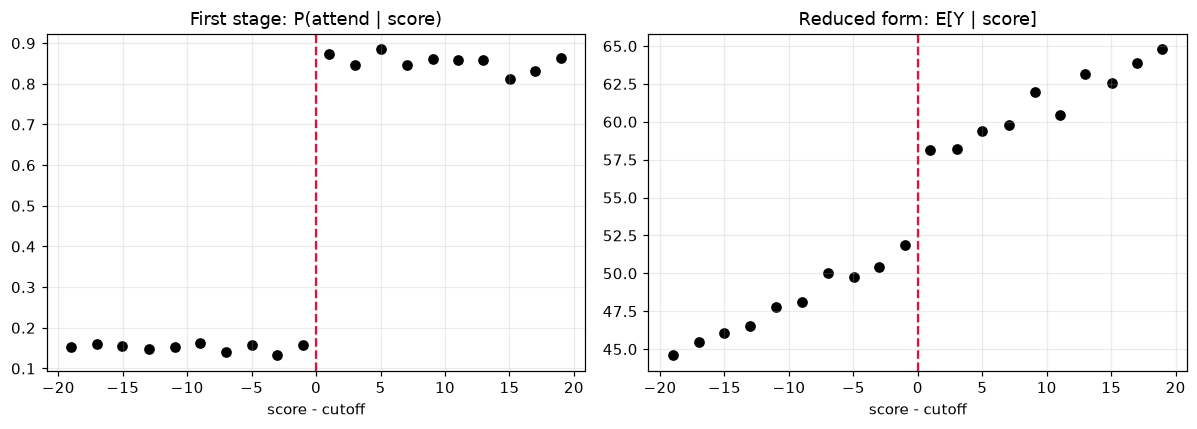

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
edges = np.linspace(-20, 20, 21)
g = ex.groupby(pd.cut(ex.score, edges), observed=True).agg(
        s=("score", "mean"), first=("attend", "mean"), rf=("Y", "mean"))
axes[0].scatter(g.s, g.first, color="black"); axes[0].set_title("First stage: P(attend | score)")
axes[1].scatter(g.s, g.rf, color="black");    axes[1].set_title("Reduced form: E[Y | score]")
for a in axes:
    a.axvline(0, color="crimson", ls="--"); a.set_xlabel("score - cutoff")
plt.tight_layout(); plt.show()

In [14]:
h  = 10
sw = ex[ex.score.abs() <= h]
fs = smf.ols("attend ~ Z + score + Z:score", data=sw).fit(cov_type="HC1")
rf = smf.ols("Y      ~ Z + score + Z:score", data=sw).fit(cov_type="HC1")

print(f"first stage jump   : {fs.params['Z']:.3f}  (se {fs.bse['Z']:.3f})")
print(f"reduced form jump  : {rf.params['Z']:.3f}  (se {rf.bse['Z']:.3f})")
print(f"Wald ratio         : {rf.params['Z']/fs.params['Z']:.2f}")
print(f"truth (complier TE): {TAU:.2f}")

print()
fz = rdrobust(y=ex.Y, x=ex.score, c=0, fuzzy=ex.attend, vce="hc1")
print(f"rdrobust fuzzy     : {fz.coef.iloc[0,0]:.2f}   "
      f"robust 95% CI [{fz.ci.iloc[2,0]:.2f}, {fz.ci.iloc[2,1]:.2f}]   h = {fz.bws.loc['h','left']:.2f}")

sharp = smf.ols("Y ~ Z + score + Z:score", data=sw).fit(cov_type="HC1").params["Z"]
naive = smf.ols("Y ~ attend + score", data=sw).fit(cov_type="HC1").params["attend"]
print(f"\nIf you ignored noncompliance (sharp RD on the offer) : {sharp:.2f}   <- ITT, too small")
print(f"If you just regressed Y on attendance               : {naive:.2f}   <- biased")

first stage jump   : 0.725  (se 0.025)
reduced form jump  : 5.242  (se 0.774)
Wald ratio         : 7.23
truth (complier TE): 8.00

rdrobust fuzzy     : 7.54   robust 95% CI [4.48, 10.32]   h = 7.53

If you ignored noncompliance (sharp RD on the offer) : 5.24   <- ITT, too small
If you just regressed Y on attendance               : 10.81   <- biased


Three numbers worth keeping straight:

* **Reduced form $\approx$ 5.2.** This is the **intention-to-treat**: the effect of *being offered* a
  seat. Often this is the policy-relevant number, since offers are what a school system
  controls.
* **Wald ratio $\approx$ 7.2**, close to the truth of 8 (and `rdrobust`, choosing its own bandwidth, gives about 7.5). The effect of *attending*, for compliers near
  the cutoff.
* **OLS of Y on attendance $\approx$ 10.8.** Badly biased upward, because always-takers are stronger students to begin with.

**Check the first stage before anything else.** If the jump in treatment probability is small,
you are dividing by something near zero and the ratio is unstable — exactly the weak-instrument
problem from last week, with all its pathologies.

### Your turn (Exercise 3)

Break it and see what happens.

In [15]:
def exam_school(p_always=0.15, p_never=0.15, direct=0.0, tau=8.0, n=6000, seed=1, h=10):
    r = np.random.default_rng(seed)
    sc = r.uniform(-20, 20, n)
    Z  = (sc >= 0).astype(int)
    u  = r.uniform(size=n)
    always, never = u < p_always, u > 1 - p_never
    att = np.where(always, 1, np.where(never, 0, Z))

    # `direct` is a violation of the exclusion restriction: the OFFER itself moves Y.
    Y = 50 + 0.4*sc + 6*always + tau*att + direct*Z + r.normal(0, 10, n)

    d  = pd.DataFrame({"score": sc, "Z": Z, "attend": att, "Y": Y})
    sw = d[d.score.abs() <= h]
    fs = smf.ols("attend ~ Z + score + Z:score", data=sw).fit(cov_type="HC1")
    rf = smf.ols("Y      ~ Z + score + Z:score", data=sw).fit(cov_type="HC1")
    o  = rdrobust(y=d.Y, x=d.score, c=0, fuzzy=d.attend, vce="hc1")
    return {"first stage": fs.params["Z"], "reduced form": rf.params["Z"],
            "Wald = RF/FS": rf.params["Z"]/fs.params["Z"],
            "rdrobust": o.coef.iloc[0, 0],
            "robust CI": f"[{o.ci.iloc[2,0]:.1f}, {o.ci.iloc[2,1]:.1f}]",
            "compliers": 1 - p_always - p_never}

scen = {
    "baseline (70% compliers)"        : exam_school(),
    "weak first stage (10% compliers)": exam_school(p_always=0.45, p_never=0.45),
    "exclusion violated (+2 on offer)": exam_school(direct=2.0),
}
print(pd.DataFrame(scen).T.round(3).to_string())
print(f"\ntruth (effect of attending, for compliers) = 8.00")

                                 first stage reduced form Wald = RF/FS   rdrobust      robust CI compliers
baseline (70% compliers)            0.707526     5.284352     7.468769    7.19662    [2.4, 11.0]       0.7
weak first stage (10% compliers)    0.041423    -0.206699    -4.989942   5.027175  [-36.1, 48.3]       0.1
exclusion violated (+2 on offer)    0.707526     7.284352    10.295519  10.258689    [5.6, 14.1]       0.7

truth (effect of attending, for compliers) = 8.00


**Answer.**

| | first stage | reduced form | Wald | robust CI |
|---|---|---|---|---|
| baseline | 0.71 | 5.3 | **7.5** | [2.4, 11.0] |
| weak first stage | 0.04 | −0.2 | **−5.0** | [−36, 48] |
| exclusion violated | 0.71 | 7.3 | **10.3** | [5.6, 14.1] |

**TODO 1 — weak first stage.** With only 10% compliers, the denominator of the Wald ratio is
0.04 and the estimate flips sign entirely, with a confidence interval spanning everything from
catastrophic to miraculous. This is the weak-instrument pathology from the IV lab in its purest
form: when the first stage is near zero, the ratio inherits all the noise in the reduced form
and amplifies it, and the usual asymptotics stop describing the sampling distribution at all.

The operational lesson: **look at the first-stage jump before you look at the ratio.** In a
fuzzy RD that means plotting $\mathbb{E}[T \mid X]$ around the cutoff and reporting the jump
with its standard error, as a table row, every time. A fuzzy RD with a 4-point jump in
treatment probability is not a research design.

**TODO 2 — exclusion violation.** Adding a direct $+2$ effect of the *offer* moves the estimate
from about 7.5 to about 10.3. The bias is almost exactly
$$\text{direct effect} / \text{first stage} = 2 / 0.71 \approx 2.8,$$
which is the IV bias formula you saw last week, with "above the cutoff" as the instrument. The
sign of the bias follows the sign of the direct effect; here the offer flatters the estimate.

**Why no test catches it.** Covariates are still perfectly balanced at the cutoff — nobody
sorted, the design is intact, the density is smooth, every placebo is null. The violation lives
in the *outcome equation*, not in who ends up on which side. Falsification tests check for
sorting; they are silent about exclusion.

That is the single most important thing to carry into your final project: **exclusion is
defended with an institutional argument, never with a test.** You have to be able to say what
else changes at the cutoff and why it cannot reach the outcome except through treatment. In the
exam-school case the honest version is uncomfortable — being told you got into a selective
school plausibly changes motivation, peer expectations, and parental investment regardless of
where you enroll, and no amount of data will separate that from the effect of attending.

## 4. RD in time (RDiT), and why it is a different animal

Davis (2008) studies *Hoy No Circula*, Mexico City's 1989 driving restriction, by comparing
pollution before and after 20 November 1989, with a polynomial in time. The running variable is
the **date**. Hausman & Rapson (2018) is a whole paper on why this is not the same design.

Three structural differences:

1. **Asymptotics are in $T$, not $N$.** In a cross-sectional RD you can add observations *at*
   the cutoff. With one city and one policy date you cannot: shrinking the bandwidth just means
   fewer days. So RDiT studies use years of data, which means identification leans on
   observations far from the threshold — precisely where the continuity argument is weakest.
2. **The manipulation test is vacuous.** The density of "time" is uniform by construction. The
   McCrary test will always pass, and it tells you nothing about whether plants complied early
   or drivers anticipated the rule.
3. **The outcome has memory.** Pollution today depends on pollution yesterday. That
   autoregression changes what the estimate even means.

Point 3 is the one you can see in a simulation. Let's reproduce Hausman & Rapson's Table 4.

The DGP: $y_t = \alpha y_{t-1} + \beta \mathbf{1}\{t \ge t_0\} + \varepsilon_t$ with
$\beta = -0.2$. The **short-run** effect is $\beta = -0.2$. The **long-run** effect, once the
series settles, is $\beta/(1-\alpha)$. A researcher who runs the usual RDiT regression with a
single post-treatment dummy and no lag gets... which one?

In [16]:
def rdit_sim(alpha, beta=-0.2, T=2920, seed=0):
    r = np.random.default_rng(seed)
    y, e, t0 = np.zeros(T), r.normal(0, 1, T), T // 2
    for t in range(1, T):
        y[t] = alpha*y[t-1] + beta*(t >= t0) + e[t]
    return y, np.arange(T) - t0

def ols(X, y):
    return np.linalg.lstsq(X, y, rcond=None)[0]

def one_draw(alpha, seed):
    y, t = rdit_sim(alpha, seed=seed)
    D, tt = (t >= 0).astype(float), t/1000
    # (a) global quartic polynomial in time, single post dummy  -- the standard RDiT spec
    gp  = ols(np.column_stack([np.ones_like(tt), D, tt, tt**2, tt**3, tt**4]), y)[1]
    # (b) local linear, 30 days each side
    m   = np.abs(t) <= 30
    loc = ols(np.column_stack([np.ones(m.sum()), D[m], tt[m], D[m]*tt[m]]), y[m])[1]
    # (c) include the lagged dependent variable
    ar  = ols(np.column_stack([np.ones(len(y)-1), D[1:], y[:-1], tt[1:]]), y[1:])[1]
    return gp, loc, ar

rows = []
for a in [0.1, 0.3, 0.5, 0.7, 0.9]:
    R = np.array([one_draw(a, s) for s in range(200)])
    rows.append({"alpha": a, "short-run truth": -0.2, "long-run truth": -0.2/(1-a),
                 "global poly": R[:,0].mean(), "(sd)": R[:,0].std(),
                 "local linear 30d": R[:,1].mean(), "(sd) ": R[:,1].std(),
                 "with lagged y": R[:,2].mean()})
print(pd.DataFrame(rows).round(2).to_string(index=False))

 alpha  short-run truth  long-run truth  global poly  (sd)  local linear 30d  (sd)   with lagged y
   0.1             -0.2           -0.22        -0.23  0.11             -0.26   0.58          -0.20
   0.3             -0.2           -0.29        -0.29  0.14             -0.33   0.72          -0.20
   0.5             -0.2           -0.40        -0.41  0.20             -0.42   0.94          -0.20
   0.7             -0.2           -0.67        -0.68  0.33             -0.58   1.36          -0.20
   0.9             -0.2           -2.00        -1.96  0.96             -0.75   2.28          -0.21


Compare that with Table 4 of Hausman & Rapson (2018). You have just reproduced it.

What it shows:

* The standard global-polynomial RDiT recovers **the long-run effect**, not the short-run one —
  and the gap explodes as the series gets more persistent. At $\alpha = 0.9$ the estimate is
  about −2.0 when the immediate impact of the policy is −0.2.
* A local linear fit near the threshold is closer to the short-run effect in principle but is
  hopelessly noisy with one series and 61 days.
* Putting the lagged dependent variable in recovers $\beta$ cleanly, and $\hat{\alpha}$ gives
  you the long-run effect too.

Neither answer is "wrong" — but you have to say which one you are reporting. For an air quality
policy, the long-run stock effect is arguably the policy-relevant one; for a one-day driving ban
it may not be.

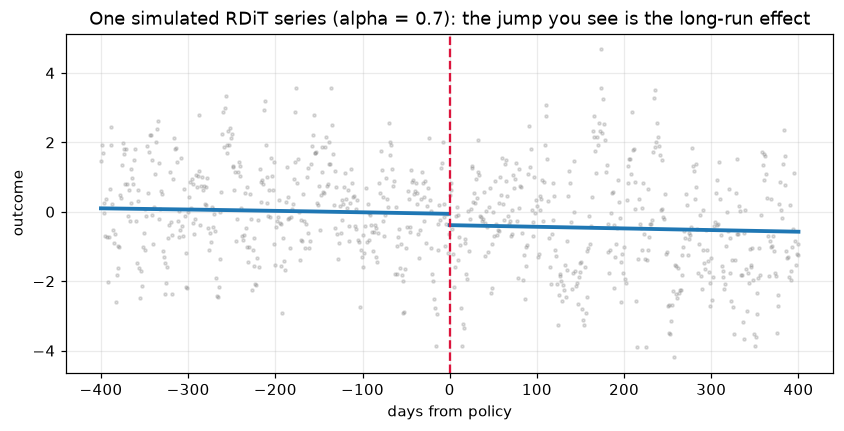

In [17]:
y, t = rdit_sim(0.7, seed=3)
D, tt = (t >= 0).astype(float), t/1000
X = np.column_stack([np.ones_like(tt), D, tt, tt**2, tt**3, tt**4])
fit = X @ ols(X, y)

fig, ax = plt.subplots(figsize=(9, 4))
keep = np.abs(t) <= 400
ax.scatter(t[keep], y[keep], s=4, alpha=.25, color="grey")
for side in [t < 0, t >= 0]:
    s = side & keep
    ax.plot(t[s], fit[s], lw=2.5, color="tab:blue")
ax.axvline(0, color="crimson", ls="--")
ax.set_title("One simulated RDiT series (alpha = 0.7): the jump you see is the long-run effect")
ax.set_xlabel("days from policy"); ax.set_ylabel("outcome")
plt.show()

### The RDiT checklist (Hausman & Rapson, section 5)

If you or your final-project coauthor uses a date as the running variable:

1. Plot the raw data, or residuals after removing weather/seasonality, with the fits overlaid.
2. Show robustness to polynomial order **and** to bandwidth — most published papers do one or
   the other, only 43% do both.
3. Run placebo tests: other dates, and untreated nearby locations.
4. Run the RD on continuous controls (weather, economic activity) to demonstrate continuity.
5. Estimate a donut RD to address anticipation and adaptation right at the date.
6. **Test for autoregression using pre-period data.** If present, include the lagged dependent
   variable and say whether you are reporting short- or long-run effects.
7. Say plainly how much of your identification comes from observations far from the threshold.

And the framing sentence from their conclusion: when $N = 1$, an RDiT is closer to an
**event study or a pre/post comparison** than to a randomized trial. Call it what it is.

This connects directly to Davis's results in the lecture slides: no detectable improvement in
air quality, no increase in transit use, more cars registered, shifted toward older
higher-emitting vehicles. The "unintended consequences" story is a behavioral response, and
behavioral responses are exactly the thing that makes a date-threshold comparison hard —
people can anticipate a policy announced in advance in a way they cannot anticipate their own
breathalyzer reading.

## 5. Writing up an RD in your final project

If your project uses an RD, the methods section needs these, in order. Anything missing will be
asked about:

1. **The rule.** Running variable, cutoff, who set it, when, what changes at it. Cite the
   statute / admissions policy / regulation.
2. **Why units cannot precisely sort.** An institutional argument first, then the density test.
3. **The plot.** Binned means plus local fits, with the bin width stated.
4. **The estimate** from `rdrobust`: bandwidth selector, kernel, polynomial order, and the
   **robust** confidence interval.
5. **Balance** on predetermined covariates, reported whether or not it passes.
6. **Robustness**: bandwidth path, polynomial order, placebo cutoffs, donut.
7. **The estimand, in a sentence.** "This is the average effect for units with a score near $c$"
   — and if fuzzy, "for compliers near $c$."
8. **What else jumps at the cutoff.** If three policies switch on at once, you estimate their
   bundle. Say so.

### Looking ahead

Next week: difference-in-differences (Mastering 'Metrics 5; Mixtape 9; The Effect 18), where
the comparison group is chosen rather than handed to you by a rule — and the credibility
problem moves from "is the cutoff manipulable" to "would these groups really have moved in
parallel."